In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df=pd.read_csv("/content/steam_games_2026.csv")
print(df.shape)
print("__________")
df.head()
df.tail()

(1000, 12)
__________


,AppID,Name,Release_Date,Primary_Genre,All_Tags,Price_USD,Discount_Pct,Review_Score_Pct,Total_Reviews,Steam_Deck_Status,Estimated_Owners,24h_Peak_Players
995,1202200,Paleo Pines,2023-09-26,Adventure,Dinosaurs;Farming Sim;Exploration;Relaxing;Ind...,7.49,75,93,1921,Unknown,57630,50
996,2753970,MARVEL Cosmic Invasion,2025-12-01,Action,Beat 'em up;Arcade;Pixel Graphics;Superhero;Co...,29.99,0,90,1630,Unknown,48900,0
997,1239080,Door Kickers 2: Task Force North,2025-02-10,Action,Tactical;Top-Down;Real Time Tactics;Real-Time ...,24.99,0,96,11539,Unknown,346170,505
998,1302240,Labyrinthine,2023-08-18,Action,Horror;Online Co-Op;Co-op;Puzzle;Psychological...,9.99,0,70,13549,Unknown,406470,179
999,917950,Vellum,2025-05-02,Action,Online Co-Op;Action Roguelike;Third-Person Sho...,11.99,40,90,1188,Unknown,35640,141


In [10]:
df.describe()

,AppID,Price_USD,Discount_Pct,Review_Score_Pct,Total_Reviews,Estimated_Owners,24h_Peak_Players
count,1.000000e+03,1000.000000,1000.000000,1000.000000,1.000000e+03,1.000000e+03,1.000000e+03
mean,1.555769e+06,21.992930,18.145000,79.658000,6.387119e+04,1.916136e+06,5.213243e+03
std,1.070126e+06,18.812135,28.613716,19.382227,2.115879e+05,6.347638e+06,4.037537e+04
min,4.000000e+02,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.667775e+05,7.790000,0.000000,75.000000,1.638250e+03,4.914750e+04,0.000000e+00
50%,1.373235e+06,19.790000,0.000000,85.000000,1.173200e+04,3.519600e+05,2.865000e+02
75%,2.359555e+06,29.990000,35.000000,92.000000,4.851575e+04,1.455472e+06,1.601000e+03
max,4.206270e+06,69.990000,95.000000,100.000000,4.980365e+06,1.494110e+08,1.013936e+06


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   AppID              1000 non-null   int64  
 1   Name               1000 non-null   object 
 2   Release_Date       999 non-null    object 
 3   Primary_Genre      1000 non-null   object 
 4   All_Tags           986 non-null    object 
 5   Price_USD          1000 non-null   float64
 6   Discount_Pct       1000 non-null   int64  
 7   Review_Score_Pct   1000 non-null   int64  
 8   Total_Reviews      1000 non-null   int64  
 9   Steam_Deck_Status  1000 non-null   object 
 10  Estimated_Owners   1000 non-null   int64  
 11  24h_Peak_Players   1000 non-null   int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 93.9+ KB


In [29]:
null_count=df.isna().sum()
print(null_count)

AppID                0
Name                 0
Release_Date         0
Primary_Genre        0
All_Tags             0
Price_USD            0
Discount_Pct         0
Review_Score_Pct     0
Total_Reviews        0
Steam_Deck_Status    0
Estimated_Owners     0
24h_Peak_Players     0
dtype: int64


In [20]:
df.loc[df['AppID'] == 242050, 'Release_Date'] = '2013-10-29'

In [23]:
df.loc[df['AppID'] == 242050, ['Name', 'Release_Date']]

,Name,Release_Date
689,Assassin’s Creed® IV Black Flag™,2013-10-29


In [22]:
rows_with_nulls = df[df.isna().any(axis=1)]
print(rows_with_nulls)

       AppID                              Name Release_Date Primary_Genre  \
0        730                  Counter-Strike 2   2012-08-21        Action   
1    2868840                  Slay the Spire 2   2026-03-05         Indie   
2    3321460                    Crimson Desert   2026-03-19        Action   
3    3065800                          Marathon   2026-03-05        Action   
4    3764200             Resident Evil Requiem   2026-02-26        Action   
..       ...                               ...          ...           ...   
995  1202200                       Paleo Pines   2023-09-26     Adventure   
996  2753970            MARVEL Cosmic Invasion   2025-12-01        Action   
997  1239080  Door Kickers 2: Task Force North   2025-02-10        Action   
998  1302240                      Labyrinthine   2023-08-18        Action   
999   917950                            Vellum   2025-05-02        Action   

                                              All_Tags  Price_USD  \
0    F

In [24]:
df['All_Tags'] = df['All_Tags'].fillna('Unknown')

In [26]:
df.drop(columns=['release_date'], inplace=True)

In [27]:
print(df.isna().sum())
print("\nDataset Shape:", df.shape)

AppID                0
Name                 0
Release_Date         0
Primary_Genre        0
All_Tags             0
Price_USD            0
Discount_Pct         0
Review_Score_Pct     0
Total_Reviews        0
Steam_Deck_Status    0
Estimated_Owners     0
24h_Peak_Players     0
dtype: int64

Dataset Shape: (1000, 12)


In [28]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate AppIDs:", df['AppID'].duplicated().sum())
print("Duplicate names:", df['Name'].duplicated().sum())

Duplicate rows: 0
Duplicate AppIDs: 0
Duplicate names: 0


In [30]:
df.dtypes


,0
AppID,int64
Name,object
Release_Date,object
Primary_Genre,object
All_Tags,object
Price_USD,float64
Discount_Pct,int64
Review_Score_Pct,int64
Total_Reviews,int64
Steam_Deck_Status,object


In [31]:
df.head()

,AppID,Name,Release_Date,Primary_Genre,All_Tags,Price_USD,Discount_Pct,Review_Score_Pct,Total_Reviews,Steam_Deck_Status,Estimated_Owners,24h_Peak_Players
0,730,Counter-Strike 2,2012-08-21,Action,FPS;Shooter;Multiplayer;Competitive;Action;Tea...,0.00,0,83,4980365,Unknown,149410950,1013936
1,2868840,Slay the Spire 2,2026-03-05,Indie,Strategy;Roguelike;Card Game;Deckbuilding;Co-o...,24.99,0,97,49549,Unknown,1486470,0
2,3321460,Crimson Desert,2026-03-19,Action,Action;Open World;Singleplayer;Adventure;Comba...,69.99,0,0,0,Unknown,0,0
3,3065800,Marathon,2026-03-05,Action,Extraction Shooter;PvP;Multiplayer;Sci-fi;Shoo...,39.99,0,90,24360,Unknown,730800,0
4,3764200,Resident Evil Requiem,2026-02-26,Action,Survival Horror;Zombies;Horror;Third-Person Sh...,69.99,0,96,79667,Unknown,2390010,0


In [32]:
df['Release_Date'] = pd.to_datetime(
    df['Release_Date'],
    errors='coerce'
)

In [33]:
print(df['Release_Date'].dtype)
display(df[['Name', 'Release_Date']].head())

datetime64[ns]


,Name,Release_Date
0,Counter-Strike 2,2012-08-21
1,Slay the Spire 2,2026-03-05
2,Crimson Desert,2026-03-19
3,Marathon,2026-03-05
4,Resident Evil Requiem,2026-02-26


In [34]:
print("Missing dates:", df['Release_Date'].isna().sum())

Missing dates: 1


In [35]:
df[df['Release_Date'].isna()][['AppID', 'Name', 'Release_Date']]

,AppID,Name,Release_Date
926,590830,s&box,NaT


In [36]:
df.loc[df['AppID'] == 590830, 'Release_Date'] = '2026-04-28'

In [37]:
print("Data type:", df['Release_Date'].dtype)
print("Missing dates:", df['Release_Date'].isna().sum())

display(df[df['AppID'] == 590830][['Name', 'Release_Date']])

Data type: datetime64[ns]
Missing dates: 0


,Name,Release_Date
926,s&box,2026-04-28


In [38]:
df.select_dtypes(include='number').describe().T

,count,mean,std,min,25%,50%,75%,max
AppID,1000.0,1.555769e+06,1.070126e+06,400.0,566777.50,1373235.00,2359555.00,4.206270e+06
Price_USD,1000.0,2.199293e+01,1.881214e+01,0.0,7.79,19.79,29.99,6.999000e+01
Discount_Pct,1000.0,1.814500e+01,2.861372e+01,0.0,0.00,0.00,35.00,9.500000e+01
Review_Score_Pct,1000.0,7.965800e+01,1.938223e+01,0.0,75.00,85.00,92.00,1.000000e+02
Total_Reviews,1000.0,6.387119e+04,2.115879e+05,0.0,1638.25,11732.00,48515.75,4.980365e+06
Estimated_Owners,1000.0,1.916136e+06,6.347638e+06,0.0,49147.50,351960.00,1455472.50,1.494110e+08
24h_Peak_Players,1000.0,5.213243e+03,4.037537e+04,0.0,0.00,286.50,1601.00,1.013936e+06


In [39]:
# Check invalid numerical values

print("Negative prices:", (df['Price_USD'] < 0).sum())

print("Invalid discounts:",
      ((df['Discount_Pct'] < 0) |
       (df['Discount_Pct'] > 100)).sum())

print("Invalid review scores:",
      ((df['Review_Score_Pct'] < 0) |
       (df['Review_Score_Pct'] > 100)).sum())

print("Negative reviews:", (df['Total_Reviews'] < 0).sum())

print("Negative peak players:",
      (df['24h_Peak_Players'] < 0).sum())

Negative prices: 0
Invalid discounts: 0
Invalid review scores: 0
Negative reviews: 0
Negative peak players: 0


In [40]:
df.select_dtypes(include='number').describe().T

,count,mean,std,min,25%,50%,75%,max
AppID,1000.0,1.555769e+06,1.070126e+06,400.0,566777.50,1373235.00,2359555.00,4.206270e+06
Price_USD,1000.0,2.199293e+01,1.881214e+01,0.0,7.79,19.79,29.99,6.999000e+01
Discount_Pct,1000.0,1.814500e+01,2.861372e+01,0.0,0.00,0.00,35.00,9.500000e+01
Review_Score_Pct,1000.0,7.965800e+01,1.938223e+01,0.0,75.00,85.00,92.00,1.000000e+02
Total_Reviews,1000.0,6.387119e+04,2.115879e+05,0.0,1638.25,11732.00,48515.75,4.980365e+06
Estimated_Owners,1000.0,1.916136e+06,6.347638e+06,0.0,49147.50,351960.00,1455472.50,1.494110e+08
24h_Peak_Players,1000.0,5.213243e+03,4.037537e+04,0.0,0.00,286.50,1601.00,1.013936e+06


In [41]:
# Check invalid numerical values

print("Negative prices:", (df['Price_USD'] < 0).sum())

print("Invalid discounts:",
      ((df['Discount_Pct'] < 0) |
       (df['Discount_Pct'] > 100)).sum())

print("Invalid review scores:",
      ((df['Review_Score_Pct'] < 0) |
       (df['Review_Score_Pct'] > 100)).sum())

print("Negative reviews:", (df['Total_Reviews'] < 0).sum())

print("Negative peak players:",
      (df['24h_Peak_Players'] < 0).sum())

Negative prices: 0
Invalid discounts: 0
Invalid review scores: 0
Negative reviews: 0
Negative peak players: 0


In [42]:
numeric_cols = [
    'Price_USD',
    'Discount_Pct',
    'Review_Score_Pct',
    'Total_Reviews',
    'Estimated_Owners',
    '24h_Peak_Players'
]

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outlier Count:", len(outliers))


Column: Price_USD
Lower Limit: -25.509999999999998
Upper Limit: 63.28999999999999
Outlier Count: 34

Column: Discount_Pct
Lower Limit: -52.5
Upper Limit: 87.5
Outlier Count: 26

Column: Review_Score_Pct
Lower Limit: 49.5
Upper Limit: 117.5
Outlier Count: 61

Column: Total_Reviews
Lower Limit: -68678.0
Upper Limit: 118832.0
Outlier Count: 126

Column: Estimated_Owners
Lower Limit: -2060340.0
Upper Limit: 3564960.0
Outlier Count: 126

Column: 24h_Peak_Players
Lower Limit: -2401.5
Upper Limit: 4002.5
Outlier Count: 149


In [43]:
for col in numeric_cols:

    print(f"\nTop 5 values in {col}")

    display(
        df.nlargest(5, col)[['Name', col]]
    )


Top 5 values in Price_USD


,Name,Price_USD
2,Crimson Desert,69.99
4,Resident Evil Requiem,69.99
9,Monster Hunter Stories 3: Twisted Reflection,69.99
34,WWE 2K26,69.99
41,DEATH STRANDING 2: ON THE BEACH,69.99



Top 5 values in Discount_Pct


,Name,Discount_Pct
278,Battlefield™ 1,95
322,Need for Speed™ Heat,95
472,Battlefield 4™,95
474,Battlefield™ V,95
564,Battlefield™ 2042,95



Top 5 values in Review_Score_Pct


,Name,Review_Score_Pct
506,The Jackbox Party Pack 3,100
947,STAR WARS™ Empire at War - Gold Pack,100
162,Funi Raccoon Game,99
422,Creature Kitchen,99
473,Crab Champions,99


... (2 outputs left out)


Top 5 values in Estimated_Owners


,Name,Estimated_Owners
0,Counter-Strike 2,149410950
57,PUBG: BATTLEGROUNDS,52726470
16,Tom Clancy's Rainbow Six Siege,37022760
158,Terraria,36032190
28,Rust,33500670



Top 5 values in 24h_Peak_Players


,Name,24h_Peak_Players
0,Counter-Strike 2,1013936
219,Dota 2,623941
57,PUBG: BATTLEGROUNDS,314682
146,ELDEN RING NIGHTREIGN,163599
28,Rust,143870


In [44]:
print("Review score above 100:",
      (df['Review_Score_Pct'] > 100).sum())

print("Discount above 100:",
      (df['Discount_Pct'] > 100).sum())

print("Negative price:",
      (df['Price_USD'] < 0).sum())

Review score above 100: 0
Discount above 100: 0
Negative price: 0


In [45]:
for col in numeric_cols:
    print(f"\nTop 5 values in {col}")

    display(
        df.nlargest(5, col)[['Name', col]]
    )


Top 5 values in Price_USD


,Name,Price_USD
2,Crimson Desert,69.99
4,Resident Evil Requiem,69.99
9,Monster Hunter Stories 3: Twisted Reflection,69.99
34,WWE 2K26,69.99
41,DEATH STRANDING 2: ON THE BEACH,69.99



Top 5 values in Discount_Pct


,Name,Discount_Pct
278,Battlefield™ 1,95
322,Need for Speed™ Heat,95
472,Battlefield 4™,95
474,Battlefield™ V,95
564,Battlefield™ 2042,95



Top 5 values in Review_Score_Pct


,Name,Review_Score_Pct
506,The Jackbox Party Pack 3,100
947,STAR WARS™ Empire at War - Gold Pack,100
162,Funi Raccoon Game,99
422,Creature Kitchen,99
473,Crab Champions,99


... (2 outputs left out)


Top 5 values in Estimated_Owners


,Name,Estimated_Owners
0,Counter-Strike 2,149410950
57,PUBG: BATTLEGROUNDS,52726470
16,Tom Clancy's Rainbow Six Siege,37022760
158,Terraria,36032190
28,Rust,33500670



Top 5 values in 24h_Peak_Players


,Name,24h_Peak_Players
0,Counter-Strike 2,1013936
219,Dota 2,623941
57,PUBG: BATTLEGROUNDS,314682
146,ELDEN RING NIGHTREIGN,163599
28,Rust,143870


In [46]:
# Create cleaned dataset
df_clean = df.copy()

# Final missing value check
print("Missing values:", df_clean.isna().sum().sum())

# Final duplicate check
print("Duplicate rows:", df_clean.duplicated().sum())

# Dataset dimensions
print("Dataset shape:", df_clean.shape)

# Verify date type
print("Release Date Type:", df_clean['Release_Date'].dtype)

Missing values: 0
Duplicate rows: 0
Dataset shape: (1000, 12)
Release Date Type: datetime64[ns]


In [49]:
# Split tags and convert them into individual rows
tags = df['All_Tags'].str.split(';').explode()

# Remove extra spaces
tags = tags.str.strip()

# Count each tag
tag_counts = tags.value_counts()

# Display top 20 tags
print(tag_counts.head(20))

All_Tags
Multiplayer     389
Action          383
Singleplayer    360
Adventure       272
RPG             263
Open World      234
Simulation      199
Co-op           188
First-Person    168
Story Rich      165
Strategy        162
Exploration     158
Online Co-Op    155
Sandbox         133
Shooter         127
FPS             123
3D              110
Survival        108
Horror          106
Fantasy         102
Name: count, dtype: int64


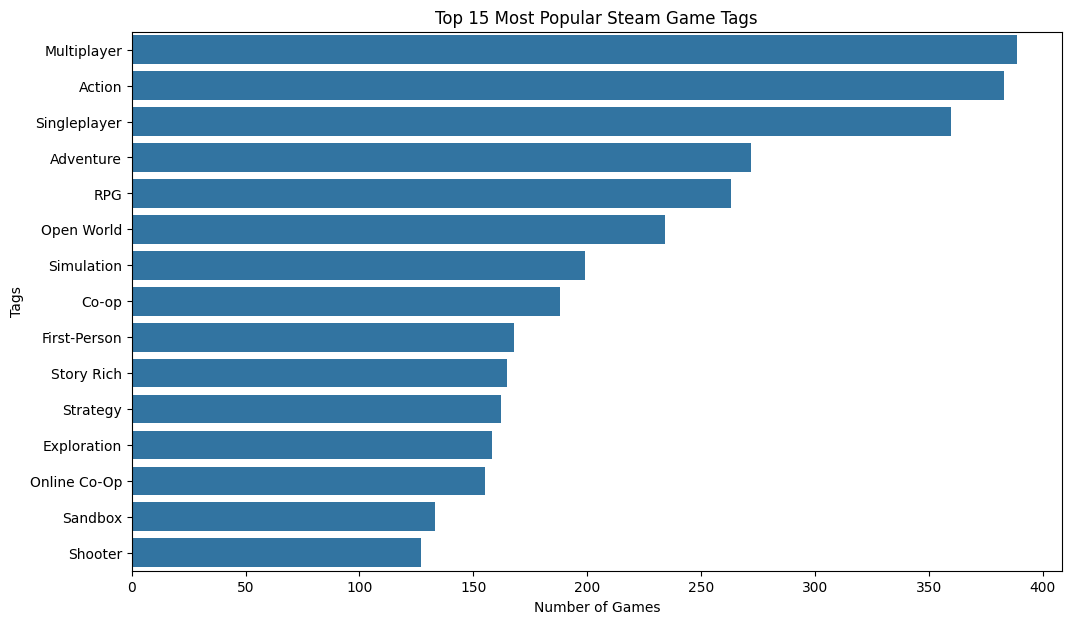

In [54]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=tag_counts.head(15).values,
    y=tag_counts.head(15).index
)

plt.title('Top 15 Most Popular Steam Game Tags')
plt.xlabel('Number of Games')
plt.ylabel('Tags')
plt.show()

In [55]:
tag_counts = df['All_Tags'].str.split(';').explode().str.strip().value_counts()

print("Total unique tags:", tag_counts.nunique())
print("\nTop 20 Tags:")
print(tag_counts.head(20))

Total unique tags: 85

Top 20 Tags:
All_Tags
Multiplayer     389
Action          383
Singleplayer    360
Adventure       272
RPG             263
Open World      234
Simulation      199
Co-op           188
First-Person    168
Story Rich      165
Strategy        162
Exploration     158
Online Co-Op    155
Sandbox         133
Shooter         127
FPS             123
3D              110
Survival        108
Horror          106
Fantasy         102
Name: count, dtype: int64


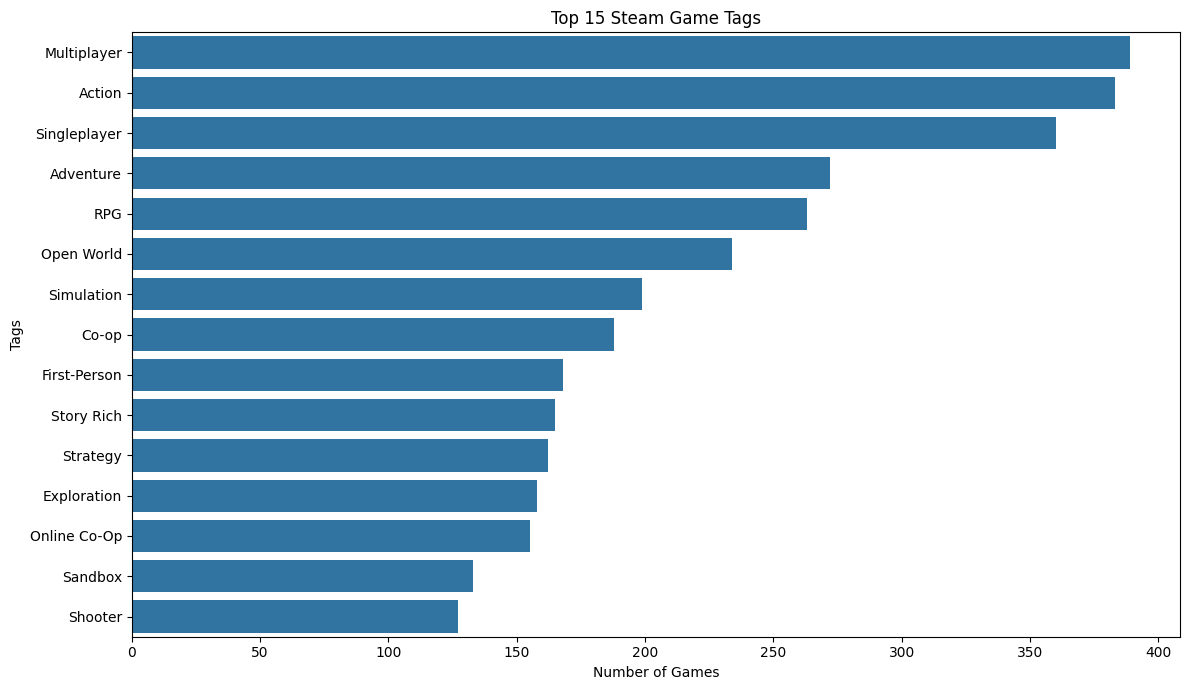

In [58]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=tag_counts.head(15).values,
    y=tag_counts.head(15).index
)

plt.title('Top 15 Steam Game Tags')
plt.xlabel('Number of Games')
plt.ylabel('Tags')
plt.tight_layout()
plt.show()

In [57]:
# Create one row per game-tag combination
tag_df = df.assign(
    Tag=df['All_Tags'].str.split(';')
).explode('Tag')

tag_df['Tag'] = tag_df['Tag'].str.strip()

# Convert metrics to numeric
tag_df['Estimated_Owners'] = pd.to_numeric(
    tag_df['Estimated_Owners'], errors='coerce'
)

tag_df['24h_Peak_Players'] = pd.to_numeric(
    tag_df['24h_Peak_Players'], errors='coerce'
)

# Calculate tag-level metrics
tag_analysis = tag_df.groupby('Tag').agg(
    Game_Count=('AppID', 'nunique'),
    Avg_Owners=('Estimated_Owners', 'mean'),
    Median_Owners=('Estimated_Owners', 'median'),
    Avg_Peak_Players=('24h_Peak_Players', 'mean'),
    Median_Peak_Players=('24h_Peak_Players', 'median')
).reset_index()

# Consider tags appearing in at least 20 games
tag_analysis = tag_analysis[tag_analysis['Game_Count'] >= 20]

# Top 15 tags by median peak players
print(
    tag_analysis.sort_values(
        'Median_Peak_Players', ascending=False
    ).head(15).round(2)
)

                           Tag  Game_Count  Avg_Owners  Median_Owners  \
188      Massively Multiplayer          37  1180774.86        28050.0   
200                   Moddable          33  4139412.73      1725570.0   
226  Open World Survival Craft          38  5658731.05      2022525.0   
312                   Survival         108  4205272.50      1353480.0   
295                 Souls-like          30  4256417.00      1699740.0   
130               Free to Play          71   186720.42         4440.0   
109                    Economy          29  1620432.41       577380.0   
45                    Building          97  2777077.73       577380.0   
358                        War          53  2022181.13       864570.0   
302                    Stealth          37  2056956.49      1345200.0   
81                    Crafting          74  3520335.41       459675.0   
297                      Space          32  2204942.81       948180.0   
225                 Open World         234  2797008

### Tag Analysis – Business Insights

The tag-level analysis indicates that Massively Multiplayer games have the highest median 24-hour peak player count (2,496) among the 15 tags examined. Free-to-Play games have the highest average peak player count (17,019.66), but their median is substantially lower (1,001), suggesting that a small number of highly popular titles may influence the average.

Moddable games have the highest median estimated ownership (1,725,570), while Open World Survival Craft games have the highest average estimated ownership (5,658,731.05) among the displayed tags.

These findings suggest that multiplayer, moddability and survival-related themes are associated with strong ownership or engagement metrics in this dataset. Further analysis is needed before drawing conclusions about the wider Steam market.

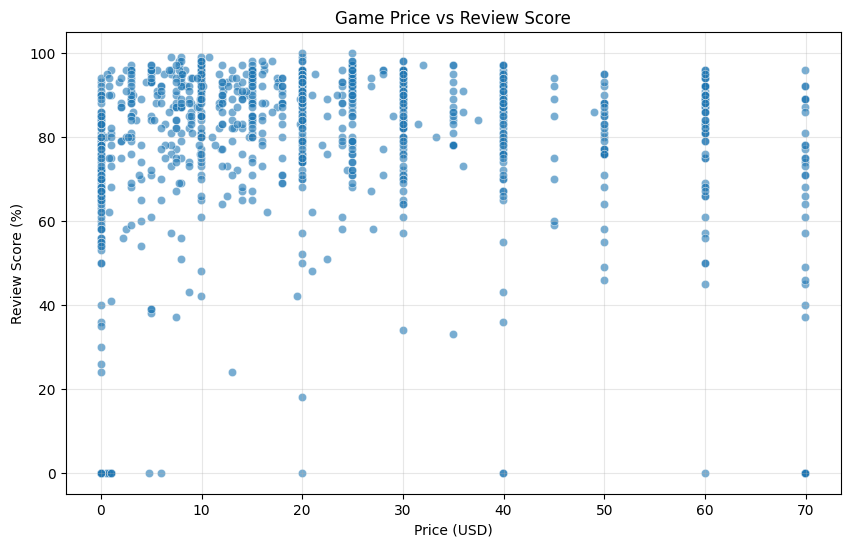

Price vs Review Score Correlation: 0.023


In [61]:
# Price vs Review Score Analysis

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Price_USD',
    y='Review_Score_Pct',
    alpha=0.6
)

plt.title('Game Price vs Review Score')
plt.xlabel('Price (USD)')
plt.ylabel('Review Score (%)')
plt.grid(alpha=0.3)
plt.show()

# Calculate correlation
correlation = df['Price_USD'].corr(df['Review_Score_Pct'])

print("Price vs Review Score Correlation:", round(correlation, 3))

In [62]:
correlation = df['Price_USD'].corr(df['Review_Score_Pct'])

print("Correlation:", round(correlation, 3))

print("\nPrice Statistics:")
print(df.groupby(
    pd.cut(df['Price_USD'], bins=[-1, 0, 10, 20, 40, 100])
)['Review_Score_Pct'].agg(['count', 'mean', 'median']).round(2))

Correlation: 0.023

Price Statistics:
           count   mean  median
Price_USD                      
(-1, 0]      108  62.39    69.5
(0, 10]      250  80.74    87.0
(10, 20]     247  85.17    88.0
(20, 40]     258  83.21    87.0
(40, 100]    137  74.66    81.0


/tmp/ipykernel_1004/3783807332.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(


### Price vs Review Score Analysis

The Pearson correlation between game price and review score is 0.023, indicating a negligible linear relationship between the two variables.

Games priced between $10 and $20 achieved the highest average review score of 85.17%, while free games had the lowest average score of 62.39%. Games priced between $40 and $100 also showed a comparatively lower average score of 74.66%.

The analysis suggests that higher game prices do not necessarily correspond to higher customer review scores. Other factors, such as gameplay quality, content, performance and player experience, may influence customer satisfaction.

In [63]:
# Convert ownership to numeric
df['Estimated_Owners'] = pd.to_numeric(
    df['Estimated_Owners'], errors='coerce'
)

# Top 10 games
top_owned = df.nlargest(10, 'Estimated_Owners')[
    ['Name', 'Primary_Genre', 'Price_USD',
     'Estimated_Owners', '24h_Peak_Players']
]

print(top_owned.to_string(index=False))

                          Name Primary_Genre  Price_USD  Estimated_Owners  24h_Peak_Players
              Counter-Strike 2        Action       0.00         149410950           1013936
           PUBG: BATTLEGROUNDS        Action       0.00          52726470            314682
Tom Clancy's Rainbow Six Siege        Action       0.00          37022760             51847
                      Terraria        Action       9.99          36032190             24580
                          Rust        Action      39.99          33500670            143870
                   Garry's Mod        Casual       9.99          31657980             18400
            Black Myth: Wukong        Action      59.99          26084400             15004
                Stardew Valley         Indie      14.99          25384500             50662
                Cyberpunk 2077           RPG      59.99          25070400             22265
      The Witcher 3: Wild Hunt           RPG      39.99          24271650       

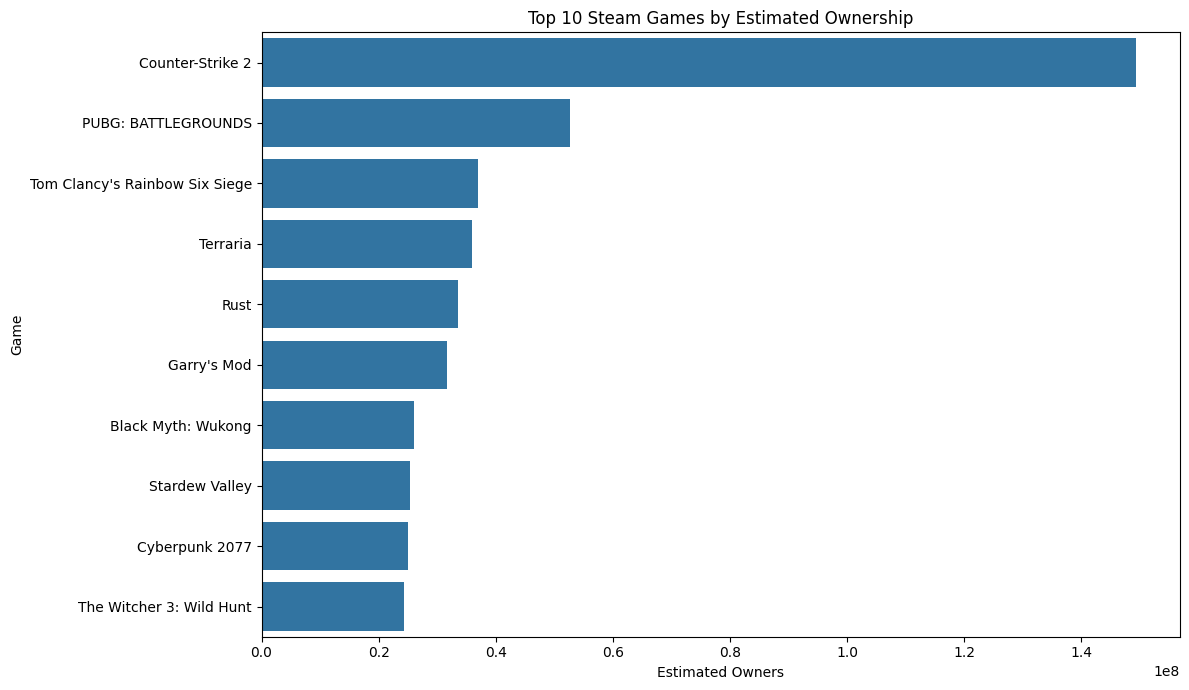

In [64]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_owned,
    x='Estimated_Owners',
    y='Name'
)

plt.title('Top 10 Steam Games by Estimated Ownership')
plt.xlabel('Estimated Owners')
plt.ylabel('Game')
plt.tight_layout()
plt.show()

### Top 10 Games by Estimated Ownership

Counter-Strike 2 ranks first with approximately 149.41 million estimated owners, followed by PUBG: BATTLEGROUNDS with 52.73 million. There is a significant gap between the first and second positions.

Action is the most represented genre, accounting for six of the ten highest-ownership games. However, games from Indie, Casual and RPG genres also demonstrate substantial ownership.

The analysis indicates that both free-to-play and premium games can achieve high estimated ownership. Estimated ownership and current player engagement should be evaluated separately because ownership does not necessarily represent active users.

In [65]:
top_engagement = df.nlargest(10, '24h_Peak_Players')[
    ['Name', 'Primary_Genre', 'Price_USD',
     'Estimated_Owners', '24h_Peak_Players']
]

print(top_engagement.to_string(index=False))

                 Name Primary_Genre  Price_USD  Estimated_Owners  24h_Peak_Players
     Counter-Strike 2        Action       0.00         149410950           1013936
               Dota 2        Action       0.00            431070            623941
  PUBG: BATTLEGROUNDS        Action       0.00          52726470            314682
ELDEN RING NIGHTREIGN        Action      39.99           3660180            163599
                 Rust        Action      39.99          33500670            143870
        Apex Legends™        Action       0.00             47310            124262
        Marvel Rivals        Action       0.00                 0            106611
            DELTARUNE         Indie      24.99           2673120             83936
        Call of Duty®        Action       0.00          12200160             67419
   NARAKA: BLADEPOINT        Action       0.00           5926740             66954


### Top 10 Games by Player Engagement

Counter-Strike 2 has the highest reported 24-hour peak player count at 1,013,936, followed by NARAKA: BLADEPOINT at 669,541 and Dota 2 at 623,941.

Action games account for nine of the ten highest-engagement titles, suggesting strong representation of the Action genre among the most actively played games in this dataset.

Both free-to-play and premium titles appear in the top 10. This indicates that high player engagement is not limited to one pricing model.

The analysis also highlights that estimated ownership and 24-hour peak players measure different aspects of game popularity and should be interpreted separately.


In [66]:
df['Release_Date'] = pd.to_datetime(
    df['Release_Date'], errors='coerce'
)

df['Release_Year'] = df['Release_Date'].dt.year

year_analysis = df.groupby('Release_Year').agg(
    Game_Count=('AppID', 'nunique'),
    Avg_Owners=('Estimated_Owners', 'mean'),
    Median_Owners=('Estimated_Owners', 'median'),
    Avg_Peak_Players=('24h_Peak_Players', 'mean')
).reset_index()

print(year_analysis.sort_values(
    'Avg_Owners', ascending=False
).round(2).to_string(index=False))

 Release_Year  Game_Count  Avg_Owners  Median_Owners  Avg_Peak_Players
         2006           1 31657980.00     31657980.0          18400.00
         2012          32  5698177.50            0.0          32891.09
         2009           6  5314790.00      1259295.0           4850.67
         2015          24  5186085.00      2407050.0           5738.96
         2018          43  3988215.35      1613820.0           6593.14
         2017          41  3472961.71      1249260.0          11206.54
         2011          15  3376142.00         6450.0           1955.47
         2014          12  3313255.00      2086365.0           6138.33
         2007           2  3191700.00      3191700.0          22228.50
         2016          40  3140385.75       575265.0           6580.38
         2020          59  2977464.92      1563330.0           5573.22
         2019          40  2685535.50      1227360.0           3439.65
         2010           5  2491668.00      1046730.0           3967.40
      

In [67]:
print("Zero estimated owners:",
      (df['Estimated_Owners'] == 0).sum())

print("\nGames by year:")
print(df.groupby('Release_Year')['Estimated_Owners']
      .agg(['count', 'min', 'median', 'max'])
      .round(2).to_string())

Zero estimated owners: 102

Games by year:
              count       min      median        max
Release_Year                                        
2006              1  31657980  31657980.0   31657980
2007              2   1390950   3191700.0    4992450
2008              3   1346040   1682070.0    1935930
2009              6    669000   1259295.0   23516460
2010              5    643920   1046730.0    6141330
2011             15         0      6450.0   36032190
2012             32         0         0.0  149410950
2013             18         0    159150.0   13281300
2014             12     78870   2086365.0   15458070
2015             24    119070   2407050.0   37022760
2016             40         0    575265.0   25384500
2017             41         0   1249260.0   52726470
2018             43         0   1613820.0   33500670
2019             40         0   1227360.0   23575800
2020             59         0   1563330.0   25070400
2021             65         0    619620.0   13432830
202

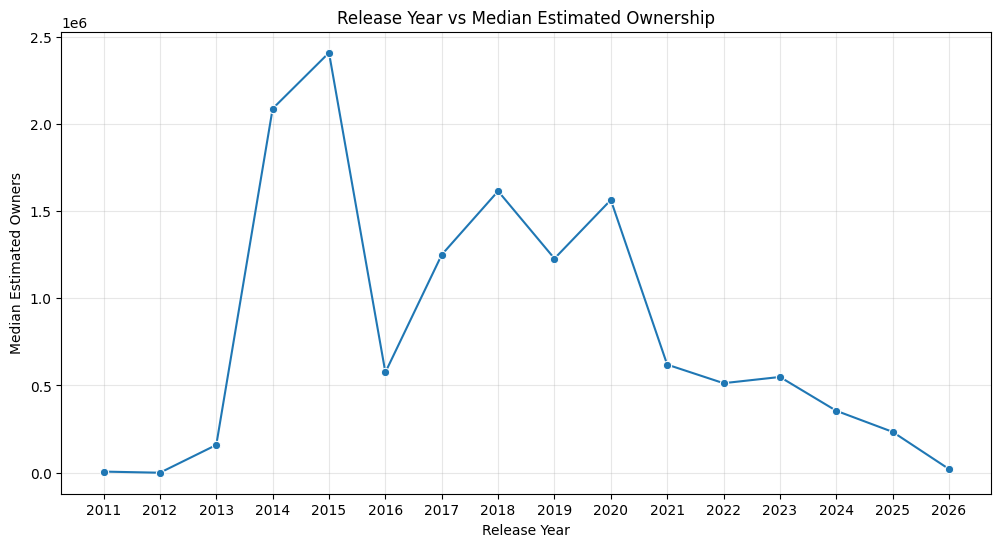

In [68]:
year_filtered = year_analysis[
    year_analysis['Game_Count'] >= 10
].sort_values('Release_Year')

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=year_filtered,
    x='Release_Year',
    y='Median_Owners',
    marker='o'
)

plt.title('Release Year vs Median Estimated Ownership')
plt.xlabel('Release Year')
plt.ylabel('Median Estimated Owners')
plt.xticks(year_filtered['Release_Year'])
plt.grid(alpha=0.3)
plt.show()

In [69]:
# Inspect games with zero estimated owners
zero_owners = df[df['Estimated_Owners'] == 0][
    ['Name', 'Release_Year',
     'Estimated_Owners', '24h_Peak_Players']
]

print("Total zero ownership records:", len(zero_owners))

print("\nZero ownership games with active players:")
print(
    zero_owners[
        zero_owners['24h_Peak_Players'] > 0
    ].to_string(index=False)
)

print("\nZero ownership games by release year:")
print(zero_owners['Release_Year'].value_counts().sort_index())

Total zero ownership records: 102

Zero ownership games with active players:
                              Name  Release_Year  Estimated_Owners  24h_Peak_Players
                     Marvel Rivals          2024                 0            106611
                        MapleStory          2012                 0              8092
                            IdleOn          2025                 0             11081
                         Wizard101          2018                 0               712
                             Palia          2024                 0              5140
                        War Robots          2018                 0              1280
                       RuneScape ®          2020                 0              2496
                   Fallout Shelter          2017                 0              1001
              Old School RuneScape          2021                 0              1050
               My Singing Monsters          2021                 0       

In [70]:
import numpy as np

# Create a separate analysis copy
df_analysis = df.copy()

# Treat zero estimated owners as missing
df_analysis.loc[
    df_analysis['Estimated_Owners'] == 0,
    'Estimated_Owners'
] = np.nan

# Recalculate yearly ownership statistics
year_analysis_clean = df_analysis.groupby('Release_Year').agg(
    Game_Count=('AppID', 'nunique'),
    Valid_Owner_Count=('Estimated_Owners', 'count'),
    Avg_Owners=('Estimated_Owners', 'mean'),
    Median_Owners=('Estimated_Owners', 'median')
).reset_index()

print(year_analysis_clean.round(2).to_string(index=False))

 Release_Year  Game_Count  Valid_Owner_Count  Avg_Owners  Median_Owners
         2006           1                  1 31657980.00     31657980.0
         2007           2                  2  3191700.00      3191700.0
         2008           3                  3  1654680.00      1682070.0
         2009           6                  6  5314790.00      1259295.0
         2010           5                  5  2491668.00      1046730.0
         2011          15                  8  6330266.25       740550.0
         2012          32                 14 13024405.71        22200.0
         2013          18                 17  2318677.06       231900.0
         2014          12                 12  3313255.00      2086365.0
         2015          24                 24  5186085.00      2407050.0
         2016          40                 36  3489317.50       797850.0
         2017          41                 39  3651062.31      1523520.0
         2018          43                 41  4182762.44      16

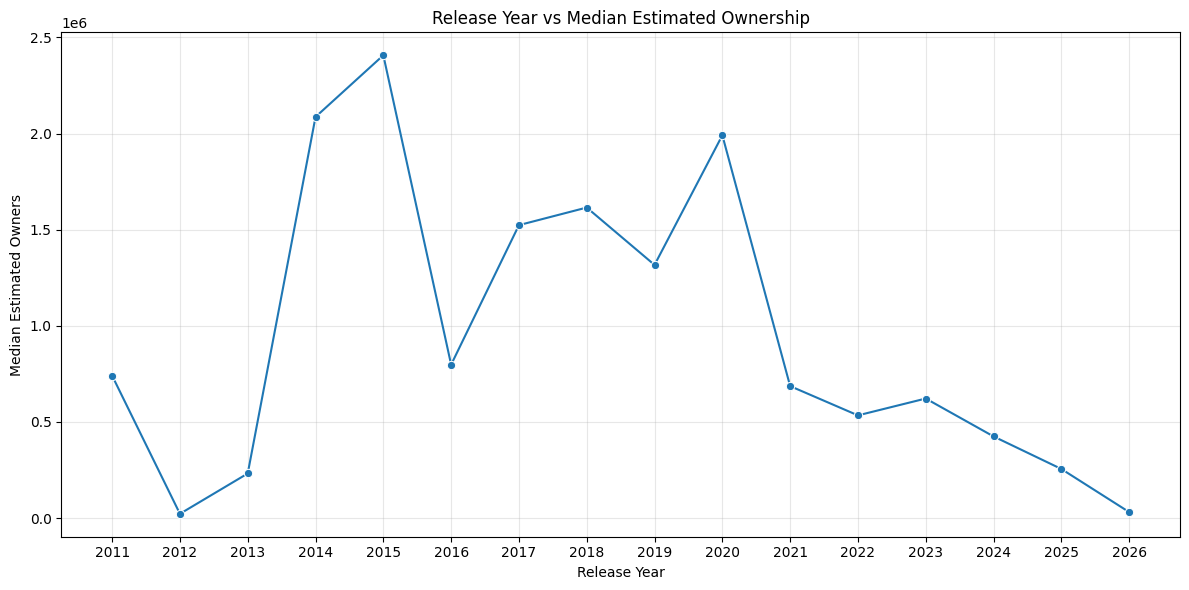

In [71]:
year_filtered = year_analysis_clean[
    year_analysis_clean['Game_Count'] >= 10
].sort_values('Release_Year')

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=year_filtered,
    x='Release_Year',
    y='Median_Owners',
    marker='o'
)

plt.title('Release Year vs Median Estimated Ownership')
plt.xlabel('Release Year')
plt.ylabel('Median Estimated Owners')
plt.xticks(year_filtered['Release_Year'])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [73]:
# 1. Row counts
print("Original rows:", len(df))
print("Cleaned rows:", len(df))
print("Rows removed:", len(df) - len(df))

# 2. Missing values in important columns
print("\nMissing values:")
print(df[
    ['AppID', 'Name', 'Primary_Genre',
     'Release_Date', 'Price_USD', 'Estimated_Owners']
].isna().sum())

# 3. Impossible values
print("\nPrice range:")
print(df['Price_USD'].min(), df['Price_USD'].max())

print("Negative prices:", (df['Price_USD'] < 0).sum())
print("Negative reviews:", (df['Total_Reviews'] < 0).sum())
print("Invalid discounts:", (
    (df['Discount_Pct'] < 0) |
    (df['Discount_Pct'] > 100)
).sum())

# 4. Analysis date range
print("\nRelease date range:")
print(df['Release_Date'].min(), df['Release_Date'].max())

# 5. Duplicate AppIDs
print("\nDuplicate AppIDs:", df.duplicated(subset=['AppID']).sum())

# 6. Ownership and peak player validation
print("\nZero estimated owners:", (df['Estimated_Owners'] == 0).sum())
print("Negative estimated owners:", (df['Estimated_Owners'] < 0).sum())
print("Negative peak players:", (df['24h_Peak_Players'] < 0).sum())

# 7. Top 10 recognisable games
print("\nTop 10 games by estimated ownership:")
print(
    df.nlargest(10, 'Estimated_Owners')[
        ['Name', 'Primary_Genre', 'Estimated_Owners']
    ].to_string(index=False)
)

Original rows: 1000
Cleaned rows: 1000
Rows removed: 0

Missing values:
AppID               0
Name                0
Primary_Genre       0
Release_Date        0
Price_USD           0
Estimated_Owners    0
dtype: int64

Price range:
0.0 69.99
Negative prices: 0
Negative reviews: 0
Invalid discounts: 0

Release date range:
2006-11-29 00:00:00 2026-07-09 00:00:00

Duplicate AppIDs: 0

Zero estimated owners: 102
Negative estimated owners: 0
Negative peak players: 0

Top 10 games by estimated ownership:
                          Name Primary_Genre  Estimated_Owners
              Counter-Strike 2        Action         149410950
           PUBG: BATTLEGROUNDS        Action          52726470
Tom Clancy's Rainbow Six Siege        Action          37022760
                      Terraria        Action          36032190
                          Rust        Action          33500670
                   Garry's Mod        Casual          31657980
            Black Myth: Wukong        Action          26

In [74]:
# Genre: how many games, and median owners per genre
print(df.groupby("Primary_Genre")["Estimated_Owners"].agg(["count", "median"]).sort_values("median", ascending=False))

# Free vs paid
df["is_free"] = df["Price_USD"] == 0
print(df.groupby("is_free")["Estimated_Owners"].agg(["count", "median"]))

# Release year trend
print(df.groupby(df["Release_Date"].dt.year)["Estimated_Owners"].agg(["count", "median"]))

                       count    median
Primary_Genre                         
Action                   579  548790.0
Racing                    17  434160.0
Simulation                47  338100.0
Strategy                  27  330420.0
Adventure                102  289560.0
Indie                     73  212730.0
Sports                     2  189510.0
Early Access               2  171705.0
Casual                    63  171120.0
RPG                       71  119070.0
Massively Multiplayer     14   42300.0
Unknown                    3       0.0
         count    median
is_free                 
False      892  436365.0
True       108       0.0
              count      median
Release_Date                   
2006              1  31657980.0
2007              2   3191700.0
2008              3   1682070.0
2009              6   1259295.0
2010              5   1046730.0
2011             15      6450.0
2012             32         0.0
2013             18    159150.0
2014             12   2086365.0
20

In [75]:
print(pd.crosstab(df["is_free"], df["Estimated_Owners"] == 0))

Estimated_Owners  False  True 
is_free                       
False               846     46
True                 52     56


In [76]:
print(df.columns.tolist())   # find your review and peak player column names

zero = df[df["Estimated_Owners"] == 0]

# Replace these with your actual column names
print(zero[["Name", "Primary_Genre", "Price_USD", "Release_Date"]].sample(15, random_state=1))
print(zero["Release_Date"].dt.year.value_counts().sort_index())
# If you have review / peak player columns:
# print((zero["Peak_Players"] > 0).sum(), (zero["Total_Reviews"] > 0).sum())

['AppID', 'Name', 'Release_Date', 'Primary_Genre', 'All_Tags', 'Price_USD', 'Discount_Pct', 'Review_Score_Pct', 'Total_Reviews', 'Steam_Deck_Status', 'Estimated_Owners', '24h_Peak_Players', 'Release_Year', 'is_free']
                                                  Name          Primary_Genre  \
946                                Ys X: Proud Nordics                 Action   
742                                   Collector's Cove                 Casual   
188                                             IdleOn                 Casual   
974                         Riichi City × Date A LiveⅤ                Unknown   
497                                        RuneScape ®  Massively Multiplayer   
789                 Phantasy Star Online 2 New Genesis                 Action   
663            Dungeon Defenders: Assault Mission Pack                 Action   
785                                    Action Taimanin                 Action   
773                                      Reverse: 1999

In [77]:
zero = df[df["Estimated_Owners"] == 0]
print((zero["Total_Reviews"] > 0).sum(), (zero["24h_Peak_Players"] > 0).sum())
print(zero[["Total_Reviews", "24h_Peak_Players"]].describe())

# DLC / add-on suspects (a heuristic, so review the list yourself)
pattern = r"\b(?:DLC|Pack|Costume|Skin|Soundtrack|Expansion|Season Pass|Bundle)\b"
df["looks_like_dlc"] = df["Name"].str.contains(pattern, case=False, regex=True)
print(df["looks_like_dlc"].sum())
print(pd.crosstab(df["looks_like_dlc"], df["Estimated_Owners"] == 0))
print(df[df["looks_like_dlc"]][["Name", "Price_USD", "Estimated_Owners"]].head(25))

0 18
       Total_Reviews  24h_Peak_Players
count          102.0        102.000000
mean             0.0       1451.343137
std              0.0      10622.380253
min              0.0          0.000000
25%              0.0          0.000000
50%              0.0          0.000000
75%              0.0          0.000000
max              0.0     106611.000000
43
Estimated_Owners  False  True 
looks_like_dlc                
False               876     81
True                 22     21
                                                  Name  Price_USD  \
284                 KINGDOM HEARTS III + Re Mind (DLC)      29.99   
369                          The Jackbox Party Pack 11      29.99   
431     Resident Evil 2 - Leon Costume: Arklay Sheriff       2.99   
432               Resident Evil 2 - Leon Costume: Noir       2.99   
433         Resident Evil 2 - Claire Costume: Military       2.99   
434             Resident Evil 2 - Claire Costume: Noir       2.99   
435      Resident Evil 2 - Claire 

In [78]:
has_rev = df["Total_Reviews"] > 0
ratio = df.loc[has_rev, "Estimated_Owners"] / df.loc[has_rev, "Total_Reviews"]
print(ratio.describe())          # if min = max = 30, confirmed
print(((df["Total_Reviews"] == 0) & (df["Estimated_Owners"] > 0)).sum())

count    898.0
mean      30.0
std        0.0
min       30.0
25%       30.0
50%       30.0
75%       30.0
max       30.0
dtype: float64
0


In [79]:
# Read all 43 flagged names yourself before trusting the flag
print(df.loc[df["looks_like_dlc"], "Name"].to_string())

# Un-flag real games with "Party Pack" (add other exceptions you spot)
df["is_dlc"] = df["looks_like_dlc"] & ~df["Name"].str.contains("Party Pack", case=False)

n0 = len(df)
a = df[~df["is_dlc"]];                        n1 = len(a)
a = a[a["Estimated_Owners"] > 0];             n2 = len(a)
a = a[a["Primary_Genre"] != "Unknown"];       n3 = len(a)

print(f"Raw: {n0} | after removing DLC: {n1} (-{n0-n1}) | "
      f"after removing zero owners: {n2} (-{n1-n2}) | "
      f"after removing Unknown genre: {n3} (-{n2-n3})")
analysis = a.copy()

284                   KINGDOM HEARTS III + Re Mind (DLC)
369                            The Jackbox Party Pack 11
431       Resident Evil 2 - Leon Costume: Arklay Sheriff
432                 Resident Evil 2 - Leon Costume: Noir
433           Resident Evil 2 - Claire Costume: Military
434               Resident Evil 2 - Claire Costume: Noir
435        Resident Evil 2 - Claire Costume: Elza Walker
436      Resident Evil 2 - Original Ver. Soundtrack Swap
488                        Resident Evil 7 - Season Pass
490                  Resident Evil Village - Trauma Pack
491           Resident Evil Village - Winters’ Expansion
506                             The Jackbox Party Pack 3
510                     Borderlands 2: Mechromancer Pack
512              Borderlands 2: Collector's Edition Pack
514    Borderlands 2: Ultimate Vault Hunters Upgrade ...
515                          Borderlands 2 - Psycho Pack
549                             The Jackbox Party Pack 7
652             Dungeon Defende

In [80]:
keep = "Party Pack|Empire at War"
df["is_dlc"] = df["looks_like_dlc"] & ~df["Name"].str.contains(keep, case=False)

In [81]:
analysis["is_free"] = analysis["Price_USD"] == 0
print(analysis["is_free"].value_counts())
print(analysis["Release_Year"].value_counts().sort_index())
analysis.to_csv("steam_games_clean.csv", index=False)

is_free
False    829
True      52
Name: count, dtype: int64
Release_Year
2006      1
2007      2
2008      3
2009      6
2010      4
2011      8
2012     12
2013     16
2014     12
2015     24
2016     34
2017     38
2018     41
2019     34
2020     54
2021     61
2022     66
2023     83
2024    113
2025    183
2026     86
Name: count, dtype: int64


In [82]:
paid = analysis[~analysis["is_free"] & analysis["Release_Year"].between(2013, 2024)]

# Genres with enough games
g = paid.groupby("Primary_Genre").agg(games=("Name","count"),
        median_owners=("Estimated_Owners","median"),
        median_score=("Review_Score_Pct","median"))
print(g[g["games"] >= 20].sort_values("median_owners", ascending=False))

# Price bands
paid = paid.assign(price_band=pd.cut(paid["Price_USD"], [0,10,20,30,50,100]))
print(paid.groupby("price_band", observed=True).agg(games=("Name","count"),
        median_owners=("Estimated_Owners","median"),
        median_score=("Review_Score_Pct","median")))

# Does a higher score go with more popularity?
print(paid[["Review_Score_Pct","Estimated_Owners"]].corr(method="spearman"))

               games  median_owners  median_score
Primary_Genre                                    
Action           313      1271970.0          87.0
Simulation        24      1043655.0          81.0
Indie             32       793395.0          93.5
Adventure         62       589425.0          90.0
Casual            26       485865.0          91.5
RPG               49       146610.0          84.0
            games  median_owners  median_score
price_band                                    
(0, 10]       147       554400.0          87.0
(10, 20]      147       710580.0          88.0
(20, 30]       99       619650.0          89.0
(30, 50]       88      1620555.0          86.0
(50, 100]      52      1773630.0          88.0
                  Review_Score_Pct  Estimated_Owners
Review_Score_Pct           1.00000           0.24901
Estimated_Owners           0.24901           1.00000
